## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [3]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012


Epoch 2/15, Loss: 1.729


Epoch 3/15, Loss: 1.627


Epoch 4/15, Loss: 1.596


Epoch 5/15, Loss: 1.582


...

Epoch 11/15, Loss: 1.550


Epoch 12/15, Loss: 1.547


Epoch 13/15, Loss: 1.545


Epoch 14/15, Loss: 1.542


Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


## Interval Analysis for class Net

In [4]:
def affine_interval(lower, upper, weight, bias):
    positive, negative = weight.clamp(min=0), weight.clamp(max=0)
    return (lower @ positive.T + upper @ negative.T + bias,
            upper @ positive.T + lower @ negative.T + bias)

@torch.no_grad()
def margin_bounds(images, labels, epsilon):
    lower = (images.double().flatten(1) - epsilon).clamp(0, 1)
    upper = (images.double().flatten(1) + epsilon).clamp(0, 1)
    lower, upper = (lower - 0.1307) / 0.3081, (upper - 0.1307) / 0.3081
    layer = model[1].fc
    lower, upper = affine_interval(lower, upper, layer.weight.double(), layer.bias.double())
    lower, upper = lower.relu(), upper.relu()
    layer = model[1].fc2
    rivals = torch.arange(10, device=labels.device).expand(len(labels), -1)
    rivals = rivals[rivals != labels[:, None]].reshape(-1, 9)
    weight = layer.weight.double()[labels, None, :] - layer.weight.double()[rivals]
    bias = layer.bias.double()[labels, None] - layer.bias.double()[rivals]
    positive, negative = weight.clamp(min=0), weight.clamp(max=0)
    lo = (positive * lower[:, None] + negative * upper[:, None]).sum(-1) + bias
    hi = (positive * upper[:, None] + negative * lower[:, None]).sum(-1) + bias
    return lo, hi

epsilon=0.01: 7055/10000, verified accuracy=70.55%


epsilon=0.02: 2368/10000, verified accuracy=23.68%


epsilon=0.03: 456/10000, verified accuracy=4.56%


epsilon=0.04: 58/10000, verified accuracy=0.58%


epsilon=0.05: 2/10000, verified accuracy=0.02%


epsilon=0.06: 0/10000, verified accuracy=0.00%


epsilon=0.07: 0/10000, verified accuracy=0.00%


epsilon=0.08: 0/10000, verified accuracy=0.00%


epsilon=0.09: 0/10000, verified accuracy=0.00%


epsilon=0.10: 0/10000, verified accuracy=0.00%


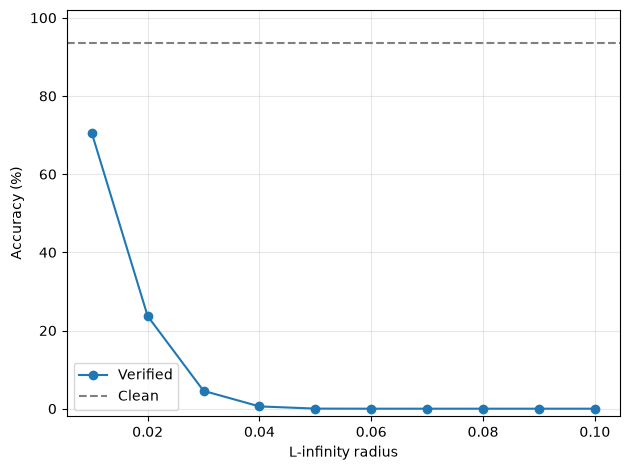

In [5]:
epsilons = np.linspace(0.01, 0.1, 10)
results = []
model.eval()
with torch.no_grad():
    clean_correct = sum((model(x.to(device)).argmax(1) == y.to(device)).sum().item()
                        for x, y in test_loader)
    for epsilon in epsilons:
        verified_count = 0
        strict_count = 0
        for images, labels in test_loader:
            lo, _ = margin_bounds(images.to(device), labels.to(device), float(epsilon))
            verified_count += (lo.amin(1) >= 0).sum().item()
            strict_count += (lo.amin(1) > 0).sum().item()
        accuracy = 100 * verified_count / len(test_dataset)
        results.append(dict(epsilon=float(epsilon), verified_count=verified_count,
                            verified_accuracy=accuracy, strict_count=strict_count))
        print(f'epsilon={epsilon:.2f}: {verified_count}/10000, verified accuracy={accuracy:.2f}%')

plt.plot(epsilons, [r['verified_accuracy'] for r in results], 'o-', label='Verified')
plt.axhline(100 * clean_correct / len(test_dataset), linestyle='--', color='gray', label='Clean')
plt.xlabel('L-infinity radius')
plt.ylabel('Accuracy (%)')
plt.ylim(-2, 102)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
from pathlib import Path
Path('results').mkdir(exist_ok=True)
plt.savefig('results/accuracy.png', dpi=180)
plt.show()


In [6]:
from pathlib import Path
import json
import csv

out = Path('results')
out.mkdir(exist_ok=True)
torch.save(model.state_dict(), out / 'mnist_15epochs.pt')
metrics = dict(epochs=15, seed=42, test_size=len(test_dataset), clean_correct=clean_correct,
               clean_accuracy=100 * clean_correct / len(test_dataset),
               torch=torch.__version__, results=results)
(out / 'metrics.json').write_text(json.dumps(metrics, indent=2) + '\n')
with (out / 'verified_accuracy.csv').open('w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=results[0].keys())
    writer.writeheader()
    writer.writerows(results)